# Phase 2 — Unsupervised Learning: K-Means (Member A)
**Project:** CCO Flight Booking & Passenger Advisory Dashboard  
**Course:** SWE485 — Group 5  
**Scope:** Member A: data preparation, K-Means, selection of k, Silhouette, Davies–Bouldin, WCSS, and reusable clustering output.

**Rationale.** K-Means is an interpretable, efficient centroid-based baseline for segmenting 50,000 airline booking records into groups with similar booking characteristics. It allows the executive dashboard to summarize passenger profiles. Because Euclidean distances depend on scale, we reuse Phase 1 preprocessing and standardize its two frequency-encoded columns. K-Means does **not** use the booking completion target; any completion-rate comparisons are strictly post-hoc descriptions, not evidence of causation.

**Limitations.** Euclidean K-Means assumes roughly compact groups and is sensitive to feature weighting, outliers, and frequency encoding, which can collapse distinct routes or countries into the same numeric value. The redundant `total_extra_services` feature also weights ancillary preferences more heavily. Results are exploratory and should be compared with Member B's alternative clustering method.

## 1. Load the processed data and remove labels

**Colab portability:** The loader checks local project paths first, then retrieves the same datasets from the project’s public GitHub repository if the files are not present. Internet access is needed only for the fallback.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

RANDOM_STATE = 42
# Prefer local project files; use the public GitHub dataset when running in a fresh Colab session.
paths = [Path('../Dataset/preprocessed_data.csv'), Path('Dataset/preprocessed_data.csv'), Path('preprocessed_data.csv')]
DATA_PATH = next((p for p in paths if p.exists()), None)
if DATA_PATH is not None:
    print('Loading processed data from:', DATA_PATH)
    data = pd.read_csv(DATA_PATH)
else:
    processed_url = ('https://raw.githubusercontent.com/Ghaida-Alyousef/'
                     'SW485-Project-Group5/main/Dataset/preprocessed_data.csv')
    print('Local processed data not found; loading from project GitHub...')
    try:
        data = pd.read_csv(processed_url)
    except Exception as exc:
        raise RuntimeError('Could not load preprocessed_data.csv from local paths or GitHub. '
                           'Check the internet connection and repository path.') from exc
assert len(data) == 50000 and {'booking_complete', 'data_split'}.issubset(data.columns)
X = data.drop(columns=['booking_complete', 'data_split']).copy()
assert X.select_dtypes(exclude='number').empty and not X.isna().any().any()
print('Data:', data.shape, '| Clustering features:', X.shape)
print('Excluded: booking_complete and data_split')

Local processed data not found; loading from project GitHub...
Data: (50000, 25) | Clustering features: (50000, 23)
Excluded: booking_complete and data_split


## 2. Feature scaling
Six numerical features were already standardized during Phase 1. Binary and one-hot indicators are left in their 0/1 representation. The frequency-encoded `route` and `booking_origin` have very small ranges, so we standardize them to avoid almost ignoring them in Euclidean distance. This is an explicit modeling choice; it increases the influence of these two columns and should be tested in sensitivity analysis. The target and split indicator never enter the scaling or clustering matrix.

In [ ]:
X_scaled = X.copy()
frequency_columns = ['route', 'booking_origin']
X_scaled[frequency_columns] = StandardScaler().fit_transform(X_scaled[frequency_columns])
X_array = X_scaled.to_numpy(dtype=np.float32)
print('Clustering matrix:', X_array.shape)

Clustering matrix: (50000, 23)


## 3. Select k: Elbow, Silhouette and Davies–Bouldin
To make the k-search practical on 50,000 records, use a deterministic random subset of 12,000 rows for candidate fitting and a fixed 1,800-row sample for Silhouette. WCSS values from this search are comparable with each other **only because the same 12,000-row sample is used**. Silhouette is maximized; Davies–Bouldin is minimized. The elbow plot is used as additional context rather than an automatic criterion.

,k,wcss,silhouette,davies_bouldin
0,2,102644.5547,0.1343,2.5459
1,3,93619.8594,0.1325,2.2353
2,4,84309.4922,0.1550,1.9185
3,5,78096.9375,0.1444,1.8493
4,6,72971.4766,0.1473,1.6886
5,7,68463.3359,0.1553,1.6252
6,8,64778.8086,0.1460,1.6861


Selected k: 7


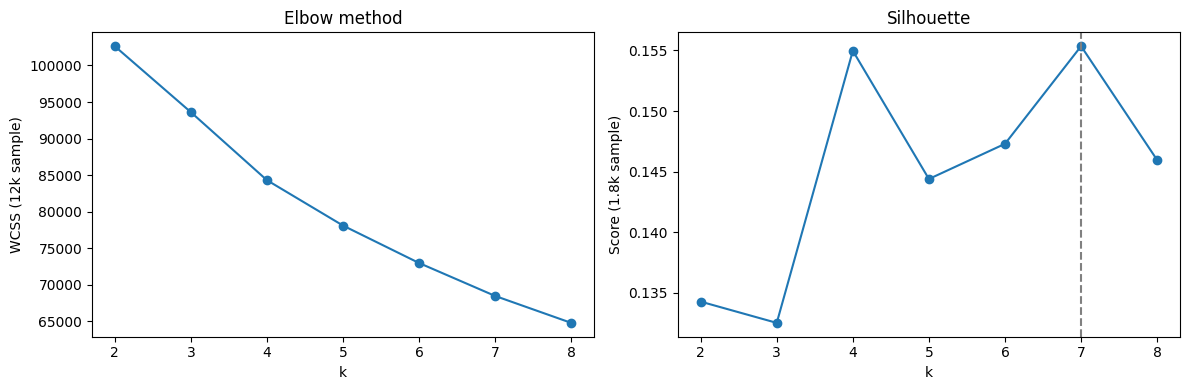

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
search_indices = rng.choice(len(X_array), size=12000, replace=False)
search_X = X_array[search_indices]
results = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE, algorithm='lloyd')
    labels = km.fit_predict(search_X)
    results.append({'k': k, 'wcss': km.inertia_,
                    'silhouette': silhouette_score(search_X, labels, sample_size=1800, random_state=RANDOM_STATE),
                    'davies_bouldin': davies_bouldin_score(search_X, labels)})
metrics = pd.DataFrame(results)
best_k = int(metrics.sort_values(['silhouette', 'davies_bouldin'], ascending=[False, True]).iloc[0]['k'])
display(metrics.round(4))
print('Selected k:', best_k)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(metrics.k, metrics.wcss, 'o-'); ax[0].set(title='Elbow method', xlabel='k', ylabel='WCSS (12k sample)')
ax[1].plot(metrics.k, metrics.silhouette, 'o-'); ax[1].axvline(best_k, linestyle='--', color='gray'); ax[1].set(title='Silhouette', xlabel='k', ylabel='Score (1.8k sample)')
plt.tight_layout(); plt.show()

## 4. Fit the final model on all 50,000 bookings
Use the selected k, with 20 initializations for stability. Final Silhouette is estimated from 2,500 sampled rows. Davies–Bouldin is evaluated on the **same** 12,000 search rows, using labels from the full-data model; this is a sample-based estimate. WCSS comes from all 50,000 records and must not be compared numerically with the 12,000-row k-search WCSS.

In [ ]:
final_model = KMeans(n_clusters=best_k, n_init=20, random_state=RANDOM_STATE, algorithm='lloyd')
cluster_labels = final_model.fit_predict(X_array)
final_silhouette = silhouette_score(X_array, cluster_labels, sample_size=2500, random_state=RANDOM_STATE)
final_db = davies_bouldin_score(X_array[search_indices], cluster_labels[search_indices])
print(f'k={best_k}; Silhouette (sampled)={final_silhouette:.4f}; Davies-Bouldin (sampled)={final_db:.4f}; Full-data WCSS={final_model.inertia_:.2f}')
print(pd.Series(cluster_labels).value_counts().sort_index())

k=7; Silhouette (sampled)=0.1540; Davies-Bouldin (sampled)=1.6248; Full-data WCSS=285413.94
0     4772
1    13272
2    16075
3     2792
4     2624
5      888
6     9577
Name: count, dtype: int64


## 5. Export reusable clustering output

In [ ]:
output = data.copy()
output.insert(0, 'row_id', np.arange(len(data)))
output['cluster'] = cluster_labels
assert len(output) == len(data) == len(cluster_labels)
assert output['row_id'].is_unique and output['cluster'].nunique() == best_k
assert output['cluster'].notna().all()
output.to_csv('clustered_data.csv', index=False)
metrics.to_csv('kmeans_k_selection.csv', index=False)
print('Saved clustered_data.csv:', output.shape)
display(output[['row_id','booking_complete','data_split','cluster']].head())

Saved clustered_data.csv: (50000, 27)


,row_id,booking_complete,data_split,cluster
0,0,0,test,0
1,1,0,train,2
2,2,0,train,0
3,3,0,train,2
4,4,0,train,6


## 6. Cluster profiles (post-hoc only)
For interpretable units, use the original raw data if available. The `booking_complete` column is used **only after fitting** to describe how observed completion rates vary across clusters. This does not make clustering supervised.

In [14]:

from pathlib import Path
from io import BytesIO
import requests

# 1. Load original raw data
raw_paths = [
    Path('../Dataset/customer_booking.csv'),
    Path('Dataset/customer_booking.csv'),
    Path('customer_booking.csv')
]

raw_path = next((p for p in raw_paths if p.exists()), None)

if raw_path is not None:
    print('Loading raw data from:', raw_path)
    raw = pd.read_csv(raw_path, encoding='latin1')
else:
    raw_url = (
        'https://raw.githubusercontent.com/Ghaida-Alyousef/'
        'SW485-Project-Group5/main/Dataset/customer_booking.csv'
    )

    print('Local raw data not found; loading from project GitHub...')

    response = requests.get(raw_url, timeout=30)
    response.raise_for_status()

    raw = pd.read_csv(
        BytesIO(response.content),
        encoding='latin1'
    )

# 2. Verify raw data matches processed data
assert len(raw) == len(data), 'Raw and processed row counts differ'

assert np.array_equal(
    raw['booking_complete'].to_numpy(),
    data['booking_complete'].to_numpy()
), 'Raw/processed row order mismatch'

# 3. Attach K-Means cluster labels
raw['cluster'] = cluster_labels

# 4. Generate cluster profiles
profiles = raw.groupby('cluster').agg(
    bookings=('booking_complete', 'size'),
    completion_rate=('booking_complete', 'mean'),
    median_purchase_lead=('purchase_lead', 'median'),
    median_length_of_stay=('length_of_stay', 'median'),
    mean_flight_duration=('flight_duration', 'mean'),
    extra_baggage_rate=('wants_extra_baggage', 'mean'),
    preferred_seat_rate=('wants_preferred_seat', 'mean'),
    meal_rate=('wants_in_flight_meals', 'mean')
)

# 5. Calculate cluster percentage
profiles['share_pct'] = profiles['bookings'] / len(raw) * 100

# 6. Save results
profiles.to_csv('kmeans_cluster_profiles.csv')

print('Raw data shape:', raw.shape)
print('Saved kmeans_cluster_profiles.csv')
display(profiles.round(3))


Local raw data not found; loading from project GitHub...
Raw data shape: (50000, 15)
Saved kmeans_cluster_profiles.csv


,bookings,completion_rate,median_purchase_lead,median_length_of_stay,mean_flight_duration,extra_baggage_rate,preferred_seat_rate,meal_rate,share_pct
cluster,,,,,,,,,
0,4772,0.142,269.0,6.0,7.133,0.538,0.208,0.271,9.544
1,13272,0.054,48.0,22.0,8.464,0.729,0.345,0.546,26.544
2,16075,0.165,36.0,6.0,6.377,0.451,0.056,0.104,32.150
3,2792,0.167,97.5,6.0,6.881,0.843,0.325,0.484,5.584
4,2624,0.211,102.0,21.0,8.830,0.675,0.227,0.451,5.248
5,888,0.133,31.0,175.0,7.729,0.882,0.390,0.592,1.776
6,9577,0.238,42.0,6.0,6.864,0.943,0.682,0.843,19.154


## 7. Cluster sizes and PCA visualization

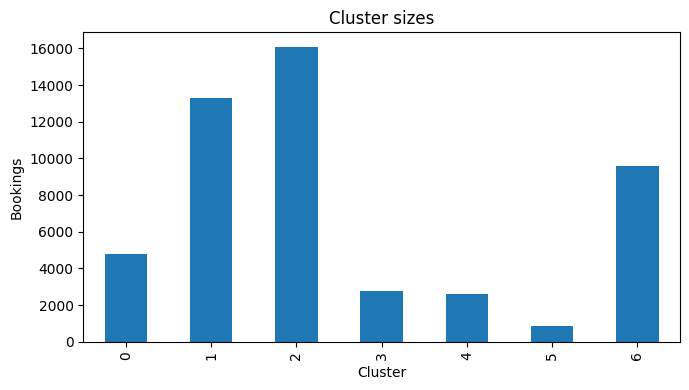

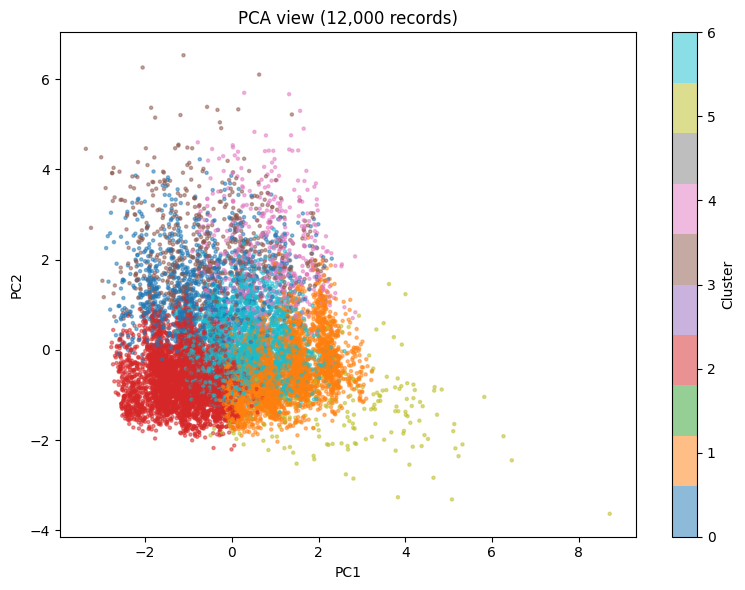

PCA explained variance: 0.30849254


In [ ]:
fig, ax = plt.subplots(figsize=(7,4))
pd.Series(cluster_labels).value_counts().sort_index().plot.bar(ax=ax)
ax.set(title='Cluster sizes',xlabel='Cluster',ylabel='Bookings');plt.tight_layout();plt.show()
pca = PCA(n_components=2, random_state=RANDOM_STATE)
projection = pca.fit_transform(X_array[search_indices])
fig, ax = plt.subplots(figsize=(8,6))
scatter = ax.scatter(projection[:,0],projection[:,1],c=cluster_labels[search_indices],s=5,alpha=.5,cmap='tab10')
fig.colorbar(scatter,ax=ax,label='Cluster');ax.set(title='PCA view (12,000 records)',xlabel='PC1',ylabel='PC2')
plt.tight_layout();plt.show()
print('PCA explained variance:', pca.explained_variance_ratio_.sum())

## 8. Interpretation, integration and challenges

**Observed results (seed 42, current saved run):** The k-search evaluated k=2–8 on the same 12,000-record subset. The highest estimated Silhouette was **0.1553 at k=7**, only **0.0003** above k=4 (0.1550); k=7 also had a lower Davies–Bouldin score (1.6252 vs 1.9185) in this search. The elbow plot has no single unmistakable bend. Therefore **k=7 is a defensible exploratory selection, not a uniquely proven optimum**. Candidate WCSS at k=7 was **68,463.34 on 12,000 rows** and must not be compared numerically with full-data WCSS.

**Final full-data K-Means:** Fitting k=7 on all **50,000** bookings yielded **Silhouette = 0.1540** (sample of 2,500), **Davies–Bouldin = 1.6248** (12,000-row subset), and **WCSS = 285,413.94** (all 50,000). Cluster sizes for IDs 0–6 were **4,772; 13,272; 16,075; 2,792; 2,624; 888; 9,577**, respectively. The relatively low Silhouette and visible overlap in PCA indicate weak separation; clusters are exploratory segments rather than sharply distinct customer types. The first two PCA components explain **30.85%** of variance, so the 2D plot cannot fully represent separation in the original 23-dimensional space.

**Business interpretation (post-hoc raw-data profiles):** Cluster 0 has long median purchase lead (**269 days**) but short median stay (**6 days**), with **14.2%** observed booking completion. Cluster 1 represents **26.54%** of records, with longer median stays (**22 days**) and **5.4%** completion. Cluster 2 is the largest (**32.15%**), has median stay **6 days** and **16.5%** completion. Cluster 3 shows high extra-baggage preference (**84.3%**) and **16.7%** completion. Cluster 4 has median stay **21 days**, mean flight duration **8.83 hours**, and **21.1%** completion. Cluster 5 is the smallest (**1.78%**), with a notably long median stay (**175 days**), potentially reflecting extreme stays or a specialized subgroup; investigate before labeling. Cluster 6 has strong ancillary preferences (extra baggage **94.3%**, preferred seat **68.2%**, meals **84.3%**) and **23.8%** completion. Completion rates are descriptive and **were not used to form clusters**; they do not establish causality.

**Integration:** Share `clustered_data.csv` with Member B and the dashboard team. Its `row_id` preserves the original row order and may be used to join Phase 1 prediction outputs **after verifying that both files use the same row ordering**. Dashboard comparisons can show segment sizes, observed completion rates, and predicted probabilities by cluster. Cluster IDs are arbitrary labels, not ranked risk scores.

**Challenges and limitations:** K-Means uses Euclidean distance, assumes reasonably compact groups, and is sensitive to outliers and feature scaling. Standardizing frequency-encoded `route` and `booking_origin` increases their weight; frequency encoding also loses category identity. One-hot features and `total_extra_services` may duplicate some preference information. The k-search covered only k=2–8 and metrics were sampled for efficiency. Before using the segments for decisions, test stability and alternative feature weights, and compare with Member B's second clustering algorithm.

**Reproducibility:** Random seed 42, K-Means with 20 initializations for final fitting. Results shown here are from the saved notebook outputs; re-running on the same input files is recommended before submission. Small differences may occur across library versions.

## 9. Algorithm 2: Gaussian Mixture Model (GMM)

### 9.1 Clustering Rationale & Algorithm Selection

K-Means (Sections 3–8) assumes that every cluster is a **round (spherical) group of roughly similar size**, and it puts each booking in exactly one cluster. To check whether the segments depend on that assumption, the second algorithm makes a **different assumption about cluster shape**.

**How GMM works.** A Gaussian Mixture Model assumes that the bookings come from *k* overlapping bell-shaped (Gaussian) distributions, called components. Each component has:
- a **mean**: the centre of the cluster, like a K-Means centroid;
- a **covariance matrix**: the size, shape and orientation of the cluster, so clusters can be stretched ellipses of different sizes;
- a **weight**: the share of bookings that belong to it.

The model is fitted with the **Expectation–Maximization (EM)** algorithm. In the *E-step*, it calculates for every booking the probability of belonging to each component. In the *M-step*, it updates the means, covariances and weights using those probabilities. The two steps repeat until the fit (log-likelihood) stops improving. Every booking therefore gets a **probability for each cluster** (soft assignment), and its label is the most likely component.

**Why GMM and not the other options:**

| Criterion | K-Means | **GMM** | DBSCAN | Hierarchical (Ward) |
| --- | --- | --- | --- | --- |
| Assumed cluster shape | Spherical, similar sizes | **Elliptical, different sizes and orientations** | Any shape, based on density | Depends on the linkage (Ward is close to spherical) |
| Assignment | One cluster per booking | **Probability for every cluster** | One cluster or "noise" | One cluster per booking |
| Works on 50,000 rows × 23 features | Yes | **Yes** (cost grows linearly with the number of rows) | Difficult: density is hard to define in 23 dimensions with many 0/1 columns, and `eps` is hard to tune | Needs every pairwise distance (about 1.25 billion for 50,000 rows), so only a sample is possible |
| Choosing the number of clusters | Elbow, silhouette | **BIC + silhouette** | Not chosen directly (`eps`, `min_samples`) | Cutting the dendrogram |

- **Dataset size and feature types:** GMM can be fitted on all 50,000 bookings. Its weak point is the 0/1 columns, which are handled in Section 9.2.
- **Expected cluster shape:** passenger groups do not have to be round or equally large. GMM relaxes exactly the assumption K-Means depends on.
- **Scalability and interpretability:** each component has a mean that can be profiled like a centroid, and the membership probability gives a **confidence** for each booking's segment, which can be shown in the dashboard and passed to the Generative AI prompts.
- **Weaknesses:** it assumes Gaussian (continuous, bell-shaped) features; with full covariance matrices it has many more parameters than K-Means; it depends on the starting point (we use several initialisations); and it is slower than K-Means.

### 9.2 Data Preparation: why GMM is fitted on PCA components

For a fair comparison, GMM uses **the same 23 features with the same scaling** as K-Means (`X_array` from Section 2), and the class label is still excluded.

However, 15 of the 23 features only take the values 0 and 1 (the three service preferences and the twelve one-hot columns). A Gaussian component can "collapse" onto bookings that share the same 0/1 value: the variance of that column inside the component becomes (almost) zero, and the covariance matrix cannot be inverted. The cell below tries GMM directly on the 23 features to show this.

In [8]:
# extra libraries for this section
import json
import time
from sklearn.mixture import GaussianMixture
from sklearn.tree import DecisionTreeClassifier
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score
import seaborn as sns

# all files from this section go to Unsupervised_Learning/clustering_results/
BASE_DIR = Path('.') if Path.cwd().name == 'Unsupervised_Learning' else Path('Unsupervised_Learning')
RESULTS_DIR = BASE_DIR / 'clustering_results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# how many features are only 0/1?
binary_cols = [c for c in X.columns if X[c].isin([0, 1]).all()]
print(f'{len(binary_cols)} of {X.shape[1]} features only take the values 0 and 1')

# first try: GMM directly on the 23 scaled features, same 12,000 bookings as the K-Means k-search
search_X64 = X_array[search_indices].astype(np.float64)
for cov_type in ['full', 'diag']:
    try:
        gmm_try = GaussianMixture(n_components=7, covariance_type=cov_type, n_init=3,
                                  random_state=RANDOM_STATE).fit(search_X64)
        try_labels = gmm_try.predict(search_X64)
        try_sil = silhouette_score(search_X64, try_labels, sample_size=5000, random_state=RANDOM_STATE)
        print(f'{cov_type:>4} covariance: fitted, silhouette = {try_sil:.3f}, '
              f'cluster sizes = {np.bincount(try_labels).tolist()}')
    except ValueError as err:
        # the error scikit-learn gives when a component's covariance collapses
        print(f'{cov_type:>4} covariance: FAILED -> {str(err)[:105]}...')

15 of 23 features only take the values 0 and 1


full covariance: fitted, silhouette = 0.020, cluster sizes = [1576, 1049, 4983, 78, 279, 3421, 614]


diag covariance: fitted, silhouette = 0.019, cluster sizes = [211, 1044, 7563, 53, 100, 2417, 612]


**Interpretation: GMM on the raw features.** Both attempts "work" technically, but the result is useless: the silhouette is about **0.02** (K-Means: 0.15), and some clusters contain only **53, 78 or 100 bookings**. These tiny clusters form around bookings that share exactly the same 0/1 values, where the variance of a column is close to zero and a Gaussian can become extremely narrow (with less precise numbers, scikit-learn can even stop with an "ill-defined covariance" error, which is why the cell catches that error). GMM's assumption of continuous, bell-shaped features is clearly violated by the 15 binary columns, so GMM cannot be used directly on this matrix.

**Solution: PCA before GMM.** PCA (Principal Component Analysis) turns the 23 correlated columns into new **continuous, uncorrelated** components, ordered by how much of the variation in the data they explain. We keep the smallest number of components that explains at least **85% of the variance**, so very little information is lost, and GMM is fitted on these components.

To keep the comparison fair, **all evaluation metrics are still calculated in the original 23-feature space**, exactly like for K-Means. PCA only changes what GMM sees during fitting.

In [9]:
# PCA on the same scaled matrix; n_components=0.85 keeps components until 85% of the variance is explained
pca_gmm = PCA(n_components=0.85, random_state=RANDOM_STATE)
Z = pca_gmm.fit_transform(X_array).astype(np.float64)   # float64 makes the covariance estimates more stable

cum_var = np.cumsum(pca_gmm.explained_variance_ratio_)
print('Components kept:', pca_gmm.n_components_, f'| variance explained: {cum_var[-1]:.1%}')
print('Cumulative variance per component:', ', '.join(f'{i + 1}: {v:.0%}' for i, v in enumerate(cum_var)))
print('GMM input matrix:', Z.shape)

Components kept: 8 | variance explained: 85.6%
Cumulative variance per component: 1: 17%, 2: 31%, 3: 43%, 4: 54%, 5: 64%, 6: 73%, 7: 80%, 8: 86%
GMM input matrix: (50000, 8)


### 9.3 Cluster Determination & Implementation

We try **k = 2 to 8** (the same range as K-Means) and two covariance types:
- `full`: every cluster can be an ellipse with any orientation (most flexible);
- `diag`: ellipses aligned with the axes (fewer parameters).

The search uses **the same 12,000 bookings as the K-Means k-search**. For each combination we record:
- **BIC** (Bayesian Information Criterion): how well the model fits, with a penalty for every extra parameter. **Lower is better.** It is GMM's own criterion, because GMM is a probability model.
- **Silhouette** (higher is better) and **Davies–Bouldin** (lower is better), both calculated in the original 23-feature space.

**Selection rule.** Silhouette and Davies–Bouldin reward compact, round, well-separated clusters, which is exactly the K-Means assumption. Using them to choose GMM's *k* would push GMM back towards K-Means and towards very few clusters. GMM is a probability model, so we use its own criterion:
1. the **covariance type** with the lower BIC;
2. the **number of components *k*** at the **first local minimum of BIC**: the first *k* after which adding one more component makes BIC worse. On large datasets BIC tends to keep decreasing slowly, so the first point where it stops improving marks where extra components stop paying for their extra parameters.

Silhouette and Davies–Bouldin are still reported here and are used to compare GMM with K-Means in Section 10.

In [10]:
search_Z = Z[search_indices]    # the same 12,000 bookings as the K-Means k-search

gmm_rows = []
for cov_type in ['full', 'diag']:
    for k in range(2, 9):
        # n_init=5: EM is started 5 times from different points and the best fit is kept
        gmm = GaussianMixture(n_components=k, covariance_type=cov_type, n_init=5,
                              max_iter=500, random_state=RANDOM_STATE)
        labels = gmm.fit(search_Z).predict(search_Z)
        gmm_rows.append({
            'covariance_type': cov_type,
            'k': k,
            'bic': gmm.bic(search_Z),
            # metrics in the original 23-feature space (search_X from Section 3), like K-Means
            'silhouette': silhouette_score(search_X, labels, sample_size=5000, random_state=RANDOM_STATE),
            'davies_bouldin': davies_bouldin_score(search_X, labels),
            'smallest_cluster': np.bincount(labels, minlength=k).min(),
        })

gmm_search = pd.DataFrame(gmm_rows)

# 1) covariance type: the one with the lower average BIC
best_cov = gmm_search.groupby('covariance_type')['bic'].mean().idxmin()
candidates = gmm_search[gmm_search['covariance_type'] == best_cov].sort_values('k').reset_index(drop=True)

# 2) k: the first local minimum of BIC, i.e. the first k after which one more component makes BIC worse
bic_values = candidates['bic'].to_numpy()
bic_rises = np.where(np.diff(bic_values) > 0)[0]
if len(bic_rises) > 0:
    best_gmm_k = int(candidates.loc[bic_rises[0], 'k'])
else:                                           # BIC never goes up: take the lowest BIC
    best_gmm_k = int(candidates.loc[bic_values.argmin(), 'k'])

display(gmm_search.round(4))
print('Covariance type with the lower BIC:', best_cov)
print('Selected number of components:', best_gmm_k)

,covariance_type,k,bic,silhouette,davies_bouldin,smallest_cluster
0,full,2,240963.5645,0.1425,2.5394,3746
1,full,3,207120.6806,0.1274,2.6890,1778
2,full,4,187004.1527,0.1172,2.6156,619
3,full,5,164461.3961,0.0948,2.8089,619
4,full,6,165551.3659,0.0930,3.0681,619
5,full,7,161213.8222,0.0564,3.2478,618
6,full,8,149762.4468,0.0524,3.4413,379
7,diag,2,257282.6250,0.1883,3.1561,2993
8,diag,3,252513.5810,0.0942,2.7609,2605
9,diag,4,247139.7989,0.1221,2.1742,824


Covariance type with the lower BIC: full
Selected number of components: 5


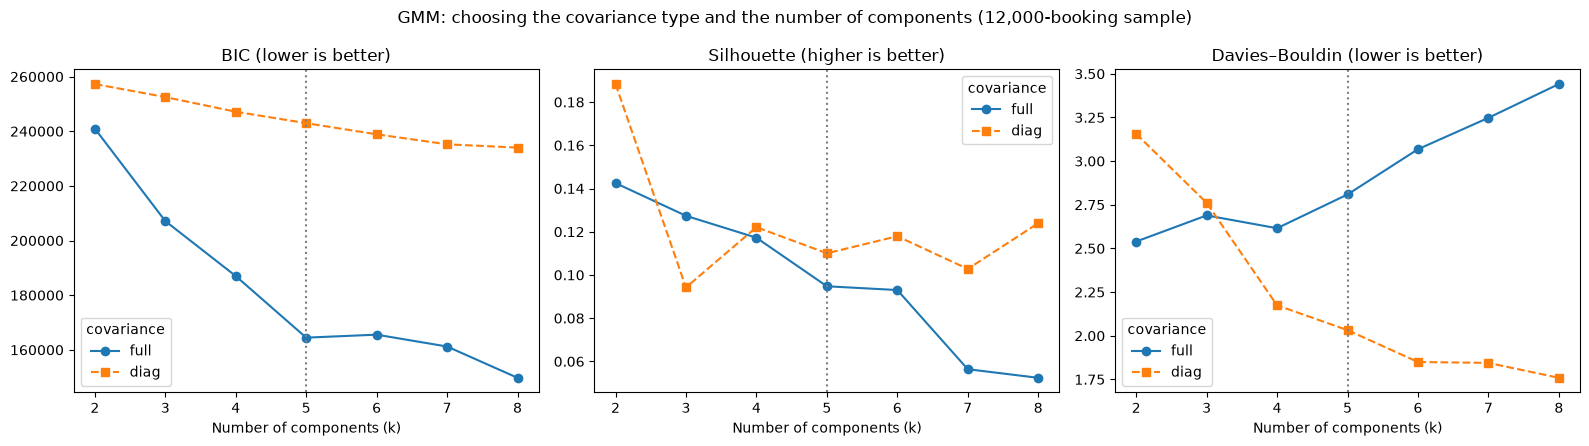

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for cov_type, style in [('full', 'o-'), ('diag', 's--')]:
    part = gmm_search[gmm_search['covariance_type'] == cov_type]
    axes[0].plot(part['k'], part['bic'], style, label=cov_type)
    axes[1].plot(part['k'], part['silhouette'], style, label=cov_type)
    axes[2].plot(part['k'], part['davies_bouldin'], style, label=cov_type)

titles = ['BIC (lower is better)', 'Silhouette (higher is better)', 'Davies–Bouldin (lower is better)']
for ax, title in zip(axes, titles):
    ax.axvline(best_gmm_k, color='gray', linestyle=':')   # the selected k
    ax.set(title=title, xlabel='Number of components (k)')
    ax.legend(title='covariance')

plt.suptitle('GMM: choosing the covariance type and the number of components (12,000-booking sample)')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'gmm_k_selection.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation: choosing the GMM.**
- **Covariance type:** `full` has a much lower BIC than `diag` for every *k* (for example 164,461 vs. 242,956 at *k* = 5). The PCA components are uncorrelated overall, but not inside each cluster, so clusters fit better as freely rotated ellipses.
- **Number of components:** for `full`, BIC drops steeply from 240,964 (*k* = 2) to **164,461 (*k* = 5)** and then **rises** to 165,551 at *k* = 6. This first local minimum gives **k = 5**. After that, BIC only improves slowly, so extra components no longer pay for their parameters.
- **Silhouette and Davies–Bouldin** get worse as *k* grows for the `full` model (silhouette 0.143 at *k* = 2 down to 0.052 at *k* = 8). Choosing *k* by silhouette would give only two clusters, which mostly separates the Australian market from everything else and is too coarse to be useful for the CCO. This confirms that these two metrics favour K-Means-style clusters.
- From *k* = 4 onwards, the smallest cluster always has about **619 bookings**. This is the AKLKUL route inside the 12,000-booking sample (about 5% of bookings), which GMM isolates in the same way as K-Means does.

**Final GMM on all 50,000 bookings.** The selected model is refitted on every booking with 10 initialisations. `predict_proba` gives each booking's probability of belonging to every cluster; the highest of these probabilities is used as the booking's **membership confidence**.

In [12]:
start = time.perf_counter()
gmm_final = GaussianMixture(n_components=best_gmm_k, covariance_type=best_cov, n_init=10,
                            max_iter=500, random_state=RANDOM_STATE).fit(Z)
gmm_fit_seconds = time.perf_counter() - start

gmm_labels = gmm_final.predict(Z)            # most likely component for each booking
gmm_proba = gmm_final.predict_proba(Z)       # one probability per component, each row sums to 1
gmm_confidence = gmm_proba.max(axis=1)       # how sure the model is about the chosen component

print(f'Converged: {gmm_final.converged_} after {gmm_final.n_iter_} EM iterations | fit time: {gmm_fit_seconds:.1f} s')
print('Cluster sizes:', pd.Series(gmm_labels).value_counts().sort_index().to_dict())
print(f'Mean membership confidence: {gmm_confidence.mean():.3f} | '
      f'bookings with confidence below 0.8: {(gmm_confidence < 0.8).mean():.1%}')

Converged: True after 36 EM iterations | fit time: 19.3 s
Cluster sizes: {0: 2680, 1: 11779, 2: 17856, 3: 11778, 4: 5907}
Mean membership confidence: 0.970 | bookings with confidence below 0.8: 4.4%


**Interpretation: final GMM.** EM converged after 36 iterations (19 seconds for 50,000 bookings with 10 initialisations). The five clusters contain **2,680, 11,779, 17,856, 11,778 and 5,907** bookings. The average membership confidence is **0.97**, and only **4.4%** of bookings have a confidence below 0.8. So even though GMM gives soft probabilities, almost every booking clearly belongs to one component, and the soft assignment adds little information here.

## 10. Evaluation Metrics & Visualizations: K-Means vs. GMM

Both algorithms are evaluated **on the same data and the same rows**:
- **K-Means labels** are read from the saved `clustered_data.csv`, which is the file shared with the team. Refitting K-Means with a different scikit-learn version can move a few bookings to another cluster, so the saved file is the reference.
- **Silhouette** is calculated on the same fixed sample of 10,000 bookings for both algorithms. This sample is larger than in Section 4, so the estimate is less noisy.
- **Davies–Bouldin** and **WCSS** (within-cluster sum of squares) are calculated on all 50,000 bookings in the 23-feature space.
- **BCubed precision and recall** (optional external check) compare the clusters with `booking_complete`, which was *not* used for clustering:
  - *precision* of a booking: the share of bookings in its cluster that have the same completion outcome;
  - *recall* of a booking: the share of all bookings with its completion outcome that ended up in its cluster.

  Both are averaged over all bookings and compared with a reference of "all bookings in one cluster".
- **Adjusted Rand Index (ARI)** measures how much the two algorithms agree (1 = identical clusters, 0 = no more agreement than chance).

In [13]:
# K-Means labels from the shared file (falls back to the labels fitted in Section 4 if the file is not found)
km_paths = [Path('Unsupervised_Learning/clustered_data.csv'), Path('../Unsupervised_Learning/clustered_data.csv'),
            Path('Dataset/clustered_data.csv'), Path('../Dataset/clustered_data.csv')]
km_path = next((p for p in km_paths if p.exists()), None)

if km_path is not None:
    saved = pd.read_csv(km_path, usecols=['row_id', 'cluster'])
    assert (saved['row_id'].to_numpy() == np.arange(len(data))).all()   # same row order as `data`
    kmeans_labels = saved['cluster'].to_numpy()
    print('K-Means labels loaded from:', km_path)
else:
    kmeans_labels = cluster_labels
    print('clustered_data.csv not found, using the K-Means labels fitted in Section 4')

print('K-Means cluster sizes:', pd.Series(kmeans_labels).value_counts().sort_index().to_dict())

K-Means labels loaded from: Unsupervised_Learning\clustered_data.csv
K-Means cluster sizes: {0: 4772, 1: 13272, 2: 16075, 3: 2792, 4: 2624, 5: 888, 6: 9577}


In [14]:
# fixed 10,000-booking sample used for the silhouette of BOTH algorithms
eval_rng = np.random.default_rng(RANDOM_STATE + 1)
eval_indices = eval_rng.choice(len(X_array), size=10000, replace=False)
X64 = X_array.astype(np.float64)


def wcss(matrix, labels):
    # sum of squared distances from every booking to the mean of its own cluster
    return sum(((matrix[labels == c] - matrix[labels == c].mean(axis=0)) ** 2).sum() for c in np.unique(labels))


def bcubed(labels, truth):
    # contingency table: one row per cluster, one column per class
    table = pd.crosstab(labels, truth).to_numpy().astype(float)
    n = table.sum()
    precision = (table ** 2 / table.sum(axis=1, keepdims=True)).sum() / n
    recall = (table ** 2 / table.sum(axis=0, keepdims=True)).sum() / n
    return precision, recall, 2 * precision * recall / (precision + recall)


truth = data['booking_complete'].to_numpy()    # only used AFTER clustering, as an external check
comparison_rows = []
for name, labels in [('K-Means', kmeans_labels), ('GMM', gmm_labels)]:
    p, r, f = bcubed(labels, truth)
    sizes = np.bincount(labels)
    comparison_rows.append({
        'algorithm': name,
        'k': len(sizes),
        'silhouette (10,000 rows)': silhouette_score(X64[eval_indices], labels[eval_indices]),
        'davies_bouldin (all rows)': davies_bouldin_score(X64, labels),
        'wcss (all rows)': wcss(X64, labels),
        'bcubed_precision': p,
        'bcubed_recall': r,
        'bcubed_f1': f,
        'smallest_cluster': sizes.min(),
        'largest_cluster': sizes.max(),
    })
comparison = pd.DataFrame(comparison_rows).set_index('algorithm')

p1, r1, f1 = bcubed(np.zeros(len(truth), dtype=int), truth)
print(f'BCubed reference, all bookings in one cluster: precision={p1:.3f}, recall={r1:.3f}, F1={f1:.3f}')
ari = adjusted_rand_score(kmeans_labels, gmm_labels)
print(f'Agreement between K-Means and GMM (ARI): {ari:.3f}')
display(comparison.round(4))

BCubed reference, all bookings in one cluster: precision=0.746, recall=1.000, F1=0.854
Agreement between K-Means and GMM (ARI): 0.364


,k,"silhouette (10,000 rows)",davies_bouldin (all rows),wcss (all rows),bcubed_precision,bcubed_recall,bcubed_f1,smallest_cluster,largest_cluster
algorithm,,,,,,,,,
K-Means,7,0.1586,1.6316,285412.9882,0.754,0.2334,0.3564,888,16075
GMM,5,0.0955,2.7609,361459.2412,0.753,0.2620,0.3887,2680,17856


**Interpretation: metrics on the same rows.**

| Metric | K-Means (k=7) | GMM (k=5) | Better |
| --- | --- | --- | --- |
| Silhouette (10,000 rows) | **0.159** | 0.096 | K-Means |
| Davies–Bouldin (all rows) | **1.632** | 2.761 | K-Means |
| WCSS (all rows) | **285,413** | 361,459 | K-Means* |
| BCubed precision / recall / F1 | 0.754 / 0.233 / 0.356 | 0.753 / 0.262 / 0.389 | see below |

- **Internal quality:** K-Means is clearly better on silhouette and Davies–Bouldin. Both silhouettes are low (well below 0.25), so both algorithms find **overlapping segments, not sharply separated groups**.
- \*WCSS always decreases when there are more clusters, and K-Means minimises WCSS directly, so this comparison favours K-Means by design and is only supporting evidence.
- **BCubed (external check against `booking_complete`):** the precision of both algorithms (0.754 and 0.753) is barely above the 0.746 of putting all bookings in a single cluster. **Neither clustering groups bookings by completion outcome**, which is expected because the label was not used. GMM's slightly higher BCubed F1 comes only from having fewer and larger clusters (higher recall), and both are below the one-cluster reference (F1 0.854). BCubed F1 therefore rewards fewer clusters here and is not a useful basis for the choice.
- **Agreement:** ARI = **0.36**, so the two algorithms only partly agree. They agree on the two segments caused by frequency encoding (the AKLKUL route and the Australian market, see below) and split the rest of the bookings differently.

### 10.1 PCA and t-SNE projections

Both plots squeeze 23 dimensions into 2, so overlap in the plot does not always mean overlap in the real data. **PCA** keeps the directions with the most variance (a linear projection). **t-SNE** is non-linear: it tries to keep similar bookings close together, so it shows local groups better, but distances between groups in a t-SNE plot are not meaningful. t-SNE is slow, so it uses 5,000 bookings.

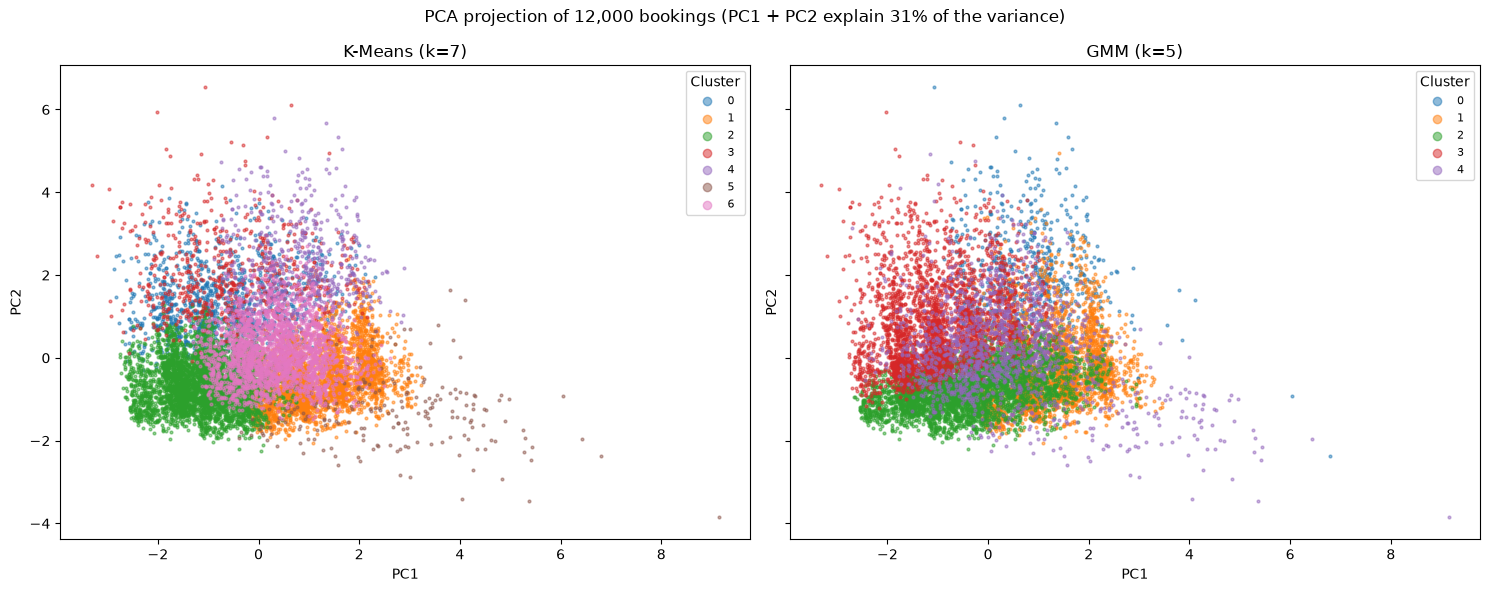

In [15]:
# 2D PCA fitted on all bookings, plotted for the 12,000-booking sample
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_array)
proj = pca_2d.transform(X_array[search_indices])

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
for ax, (name, labels) in zip(axes, [('K-Means', kmeans_labels), ('GMM', gmm_labels)]):
    sample_labels = labels[search_indices]
    for c in np.unique(sample_labels):          # one colour per cluster number, the same in every plot
        pts = proj[sample_labels == c]
        ax.scatter(pts[:, 0], pts[:, 1], s=4, alpha=0.5, color=plt.cm.tab10(c % 10), label=str(c))
    ax.set(title=f'{name} (k={len(np.unique(labels))})', xlabel='PC1', ylabel='PC2')
    ax.legend(title='Cluster', loc='upper right', fontsize=8, markerscale=3)
plt.suptitle(f'PCA projection of 12,000 bookings (PC1 + PC2 explain {pca_2d.explained_variance_ratio_.sum():.0%} of the variance)')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'pca_kmeans_vs_gmm.png', dpi=150, bbox_inches='tight')
plt.show()

t-SNE took 9 s


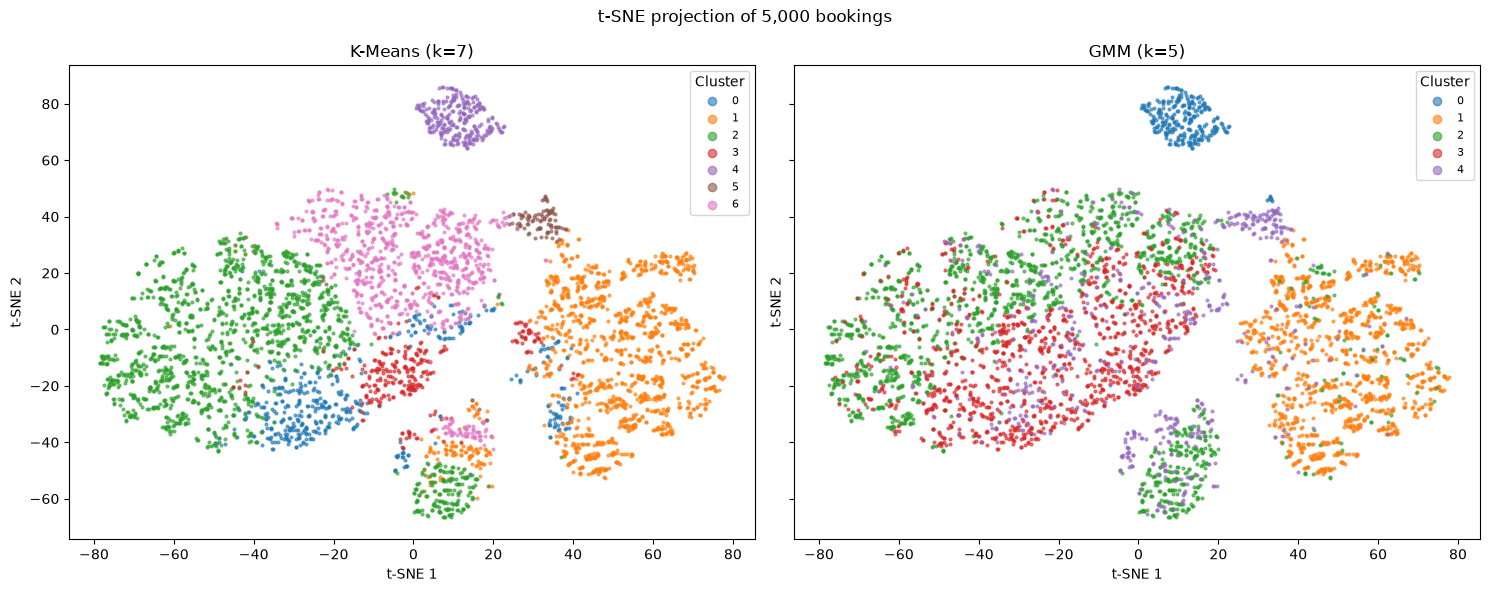

In [16]:
# t-SNE on 5,000 bookings from the evaluation sample (the same embedding is coloured by both algorithms)
tsne_idx = eval_indices[:5000]
start = time.perf_counter()
emb = TSNE(n_components=2, perplexity=30, init='pca', random_state=RANDOM_STATE).fit_transform(X_array[tsne_idx])
print(f't-SNE took {time.perf_counter() - start:.0f} s')

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
for ax, (name, labels) in zip(axes, [('K-Means', kmeans_labels), ('GMM', gmm_labels)]):
    sample_labels = labels[tsne_idx]
    for c in np.unique(sample_labels):
        pts = emb[sample_labels == c]
        ax.scatter(pts[:, 0], pts[:, 1], s=4, alpha=0.6, color=plt.cm.tab10(c % 10), label=str(c))
    ax.set(title=f'{name} (k={len(np.unique(labels))})', xlabel='t-SNE 1', ylabel='t-SNE 2')
    ax.legend(title='Cluster', loc='upper right', fontsize=8, markerscale=3)
plt.suptitle('t-SNE projection of 5,000 bookings')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'tsne_kmeans_vs_gmm.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation: projections.** In the PCA plot, PC1 and PC2 only explain 31% of the variance, and the clusters of both algorithms overlap heavily, which matches the low silhouette values. The t-SNE plot shows the structure more clearly:
- The **AKLKUL route** forms a separate island at the top, and **both** algorithms find it (K-Means cluster 4, GMM cluster 0). The **Australian market** fills the right-hand region (cluster 1 in both).
- In the remaining bookings, K-Means splits the area into readable behaviour groups: short trips with few extras (2), extra-service lovers (6), early planners (0), groups (3) and the small long-stay island (5).
- GMM mixes its clusters 2 and 3 across the same area, so its groups are harder to see and describe.

### 10.2 Cluster size distribution

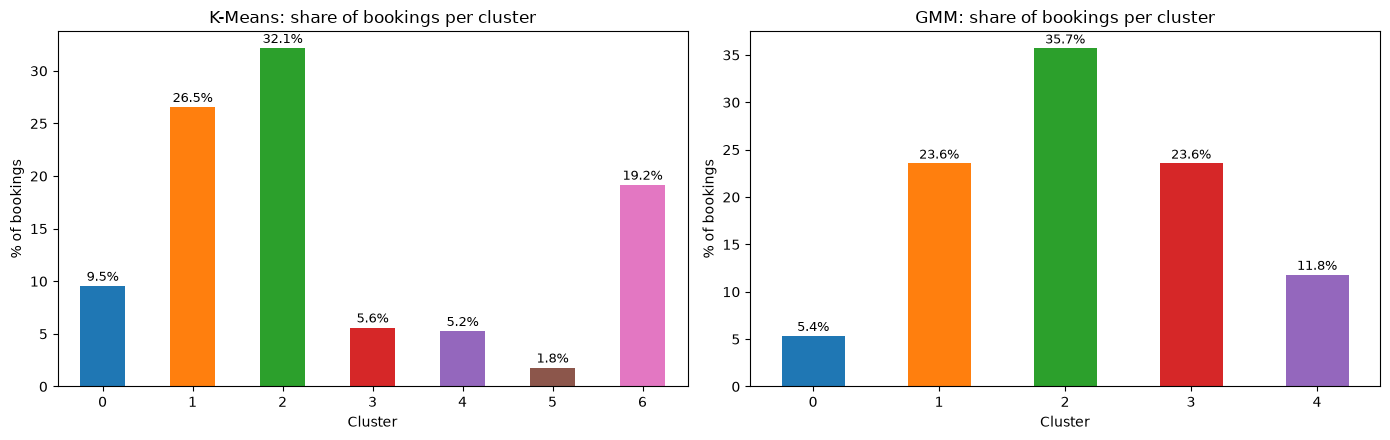

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (name, labels) in zip(axes, [('K-Means', kmeans_labels), ('GMM', gmm_labels)]):
    share = pd.Series(labels).value_counts(normalize=True).sort_index() * 100
    share.plot.bar(ax=ax, color=plt.cm.tab10(share.index.to_numpy() % 10))
    for i, v in enumerate(share):
        ax.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=9)
    ax.set(title=f'{name}: share of bookings per cluster', xlabel='Cluster', ylabel='% of bookings')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'cluster_sizes_kmeans_vs_gmm.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation: cluster sizes.** K-Means segments range from **1.8%** (long-stay travellers) to **32.1%** of bookings, and GMM components from **5.4%** to **35.7%**. Neither algorithm produces a single giant cluster. The small K-Means segments (long stays, groups and AKLKUL, about 2–6% each) are still large enough to act on: the smallest has 888 bookings.

### 10.3 Feature importance per cluster

Two views explain which features define the clusters:
1. **Heatmap of cluster means.** For every cluster, the average value of each feature in the clustering matrix. For scaled features, 0 is the overall average and ±1 is one standard deviation; for 0/1 features, the value is the share of bookings with that value.
2. **Surrogate decision tree.** A small decision tree (depth 5, as in the lecture's decision trees) is trained to predict each booking's cluster from the 23 features. Its feature importance shows which features separate the clusters, and its accuracy on bookings it did not see shows how easy the clusters are to describe with simple rules.

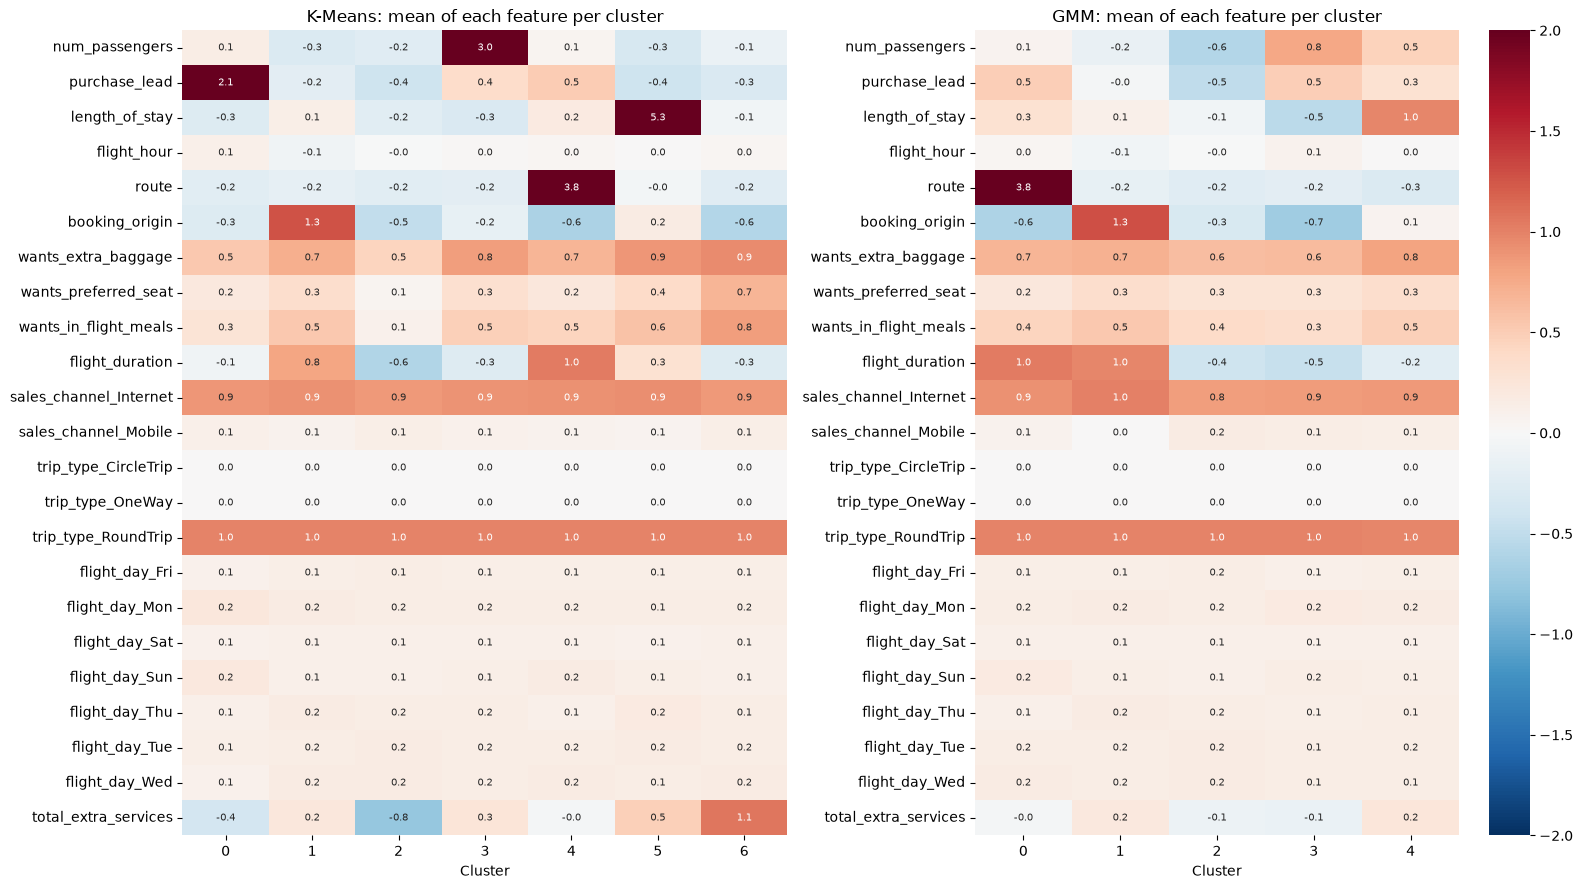

In [18]:
X_for_profile = X_scaled.copy()    # the clustering matrix as a table, with column names

fig, axes = plt.subplots(1, 2, figsize=(16, 9))
for ax, (name, labels) in zip(axes, [('K-Means', kmeans_labels), ('GMM', gmm_labels)]):
    means = X_for_profile.groupby(labels).mean().T     # rows = features, columns = clusters
    sns.heatmap(means, cmap='RdBu_r', center=0, vmin=-2, vmax=2, annot=True, fmt='.1f',
                annot_kws={'size': 7}, cbar=(name == 'GMM'), ax=ax)
    ax.set(title=f'{name}: mean of each feature per cluster', xlabel='Cluster', ylabel='')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'feature_means_per_cluster.png', dpi=150, bbox_inches='tight')
plt.show()

K-Means: a depth-5 tree reproduces the clusters with 95.3% accuracy on unseen bookings
GMM: a depth-5 tree reproduces the clusters with 98.2% accuracy on unseen bookings


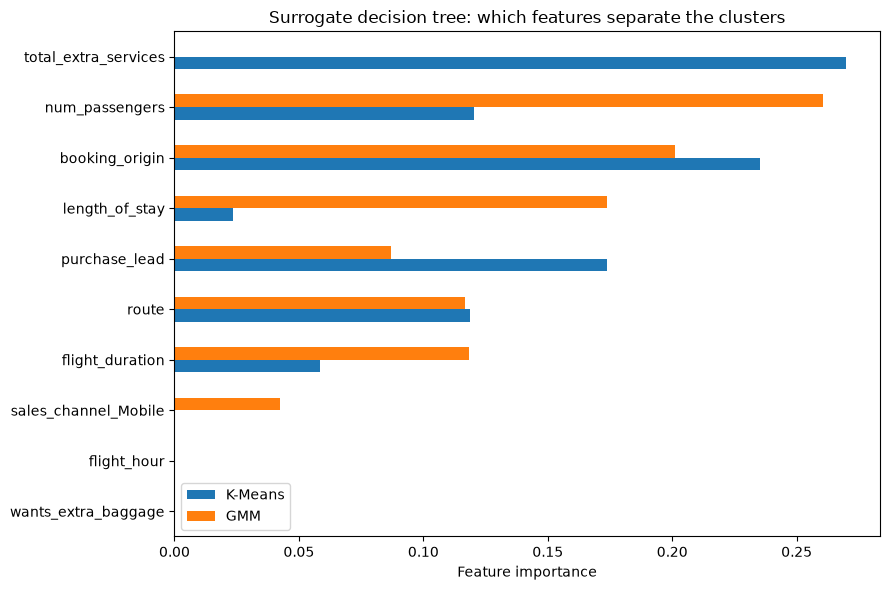

In [19]:
# surrogate tree: trained on bookings outside the evaluation sample, tested on the 10,000 evaluation bookings
train_mask = np.ones(len(X_array), dtype=bool)
train_mask[eval_indices] = False

importance = {}
for name, labels in [('K-Means', kmeans_labels), ('GMM', gmm_labels)]:
    tree = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)
    tree.fit(X_for_profile[train_mask], labels[train_mask])
    acc = tree.score(X_for_profile.iloc[eval_indices], labels[eval_indices])
    importance[name] = pd.Series(tree.feature_importances_, index=X_for_profile.columns)
    print(f'{name}: a depth-5 tree reproduces the clusters with {acc:.1%} accuracy on unseen bookings')

importance = pd.DataFrame(importance)
top = importance.max(axis=1).sort_values(ascending=False).head(10).index   # 10 most important features overall
importance.loc[top[::-1]].plot.barh(figsize=(9, 6))
plt.title('Surrogate decision tree: which features separate the clusters')
plt.xlabel('Feature importance')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'surrogate_tree_importance.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation: feature importance per cluster.**
- **K-Means:** every cluster has one clear signature in the heatmap: number of passengers (+3.0 standard deviations in cluster 3), purchase lead (+2.1 in cluster 0), length of stay (+5.3 in cluster 5), route (+3.8 in cluster 4), booking origin (+1.3 in cluster 1) and extra services (+1.1 in cluster 6 and −0.8 in cluster 2). A depth-5 tree reproduces the K-Means clusters with **95.3%** accuracy, mainly using `total_extra_services`, `booking_origin`, `purchase_lead`, `num_passengers` and `route`. The segments can therefore be explained with simple rules.
- **GMM:** only two clusters have a strong signature, namely route (+3.8, the AKLKUL cluster) and booking origin (+1.3, Australia). The other three differ mainly in `num_passengers` and `length_of_stay`. Its surrogate tree reaches **98.2%**, but mostly by splitting on `num_passengers`: GMM cluster 2 contains **only single-passenger bookings**. Number of passengers is a count, not a continuous value, so GMM separates the bookings with exactly one passenger, which is another effect of its Gaussian assumption.
- For **both** algorithms, flight day, trip type and sales channel are almost the same in every cluster, so they do not define any segment.

## 11. Algorithm Comparison & Final Choice

In [20]:
# running time: refit K-Means once on all bookings with the same settings as Section 4, only to time it
start = time.perf_counter()
KMeans(n_clusters=len(np.unique(kmeans_labels)), n_init=20, random_state=RANDOM_STATE, algorithm='lloyd').fit(X_array)
kmeans_fit_seconds = time.perf_counter() - start

summary = comparison[['k', 'silhouette (10,000 rows)', 'davies_bouldin (all rows)', 'bcubed_f1']].copy()
summary['fit time on 50,000 rows (s)'] = [kmeans_fit_seconds, gmm_fit_seconds]
summary['membership'] = ['hard (one cluster)', 'soft (probabilities)']
display(summary.round(4))

,k,"silhouette (10,000 rows)",davies_bouldin (all rows),bcubed_f1,"fit time on 50,000 rows (s)",membership
algorithm,,,,,,
K-Means,7,0.1586,1.6316,0.3564,1.9840,hard (one cluster)
GMM,5,0.0955,2.7609,0.3887,19.3375,soft (probabilities)


### Final choice: **K-Means (k = 7)**

| Criterion | K-Means | GMM |
| --- | --- | --- |
| Silhouette / Davies–Bouldin | **0.159 / 1.63** | 0.096 / 2.76 |
| Fit to the data type | Works on mixed 0/1 and scaled features | Needs PCA first, because the Gaussian assumption fails on 0/1 columns |
| Interpretability | **Seven segments, each with one clear signature** (groups, early planners, long stays, extra services…) | Two encoding-driven clusters plus three overlapping ones, one of them defined only by "exactly one passenger" |
| Speed on 50,000 bookings | **About 1–2 s** | About 19 s |
| Extra information | One segment per booking | A membership probability, but 96% of bookings are already above 0.8 |
| Usefulness for the dashboard and GenAI | **Segments map directly to actions and prompt context** | Harder to explain to an executive audience |

**Justification.** K-Means is better on both internal metrics measured on the same rows, its segments are easier to explain (a small decision tree reproduces 95% of them), it is about ten times faster, and its labels are already shared with the team in `clustered_data.csv`. The main advantage of GMM, soft membership, adds little here because almost every booking is assigned with high confidence. Testing GMM was still useful: it showed that the **Australian market and the AKLKUL route are found by both algorithms**, while the behaviour-based segments are specific to K-Means and should be presented as exploratory segments, not fixed customer types.

## 12. Cluster Interpretation & Profiles

The profiles below describe the **final segments**, using the original (unscaled) values from `customer_booking.csv` so that they are easy to read. `booking_complete` is only used **after** clustering, to describe each segment; it was never used to form the clusters.

Cluster numbers are arbitrary, so every segment gets a name. The names are assigned automatically from each cluster's most distinctive statistic (for example, the cluster with the highest average number of passengers is "Group travellers"), which keeps them correct even if the cluster numbers change.

In [21]:
segments = raw.drop(columns=['cluster'], errors='ignore').copy()   # original values, same row order as `data`
segments['segment'] = kmeans_labels

top_origin = segments['booking_origin'].value_counts().index[0]   # the largest market
top_route = segments['route'].value_counts().index[0]             # the busiest route

profiles_final = segments.groupby('segment').agg(
    bookings=('segment', 'size'),
    completion_rate=('booking_complete', 'mean'),
    median_purchase_lead=('purchase_lead', 'median'),
    median_length_of_stay=('length_of_stay', 'median'),
    mean_passengers=('num_passengers', 'mean'),
    mean_flight_duration=('flight_duration', 'mean'),
    extra_baggage_rate=('wants_extra_baggage', 'mean'),
    preferred_seat_rate=('wants_preferred_seat', 'mean'),
    meal_rate=('wants_in_flight_meals', 'mean'),
    mobile_rate=('sales_channel', lambda s: (s == 'Mobile').mean()),
    top_origin_share=('booking_origin', lambda s: (s == top_origin).mean()),
    top_route_share=('route', lambda s: (s == top_route).mean()),
)
profiles_final['share_pct'] = profiles_final['bookings'] / len(segments) * 100
profiles_final['service_score'] = profiles_final[['extra_baggage_rate', 'preferred_seat_rate', 'meal_rate']].mean(axis=1)

# name each segment after its most distinctive statistic (each rule must pick a different cluster)
rules = [
    (f'Top market ({top_origin})', 'top_origin_share'),
    (f'Top route ({top_route})', 'top_route_share'),
    ('Group travellers', 'mean_passengers'),
    ('Long-stay travellers', 'median_length_of_stay'),
    ('Early planners', 'median_purchase_lead'),
    ('Extra-service lovers', 'service_score'),
]
names = {}
for name, column in rules:
    remaining = profiles_final.drop(index=list(names))
    names[remaining[column].idxmax()] = name
for c in profiles_final.index:          # whatever is left is the general group
    names.setdefault(c, 'Short trips, few extras')
profiles_final.insert(0, 'name', profiles_final.index.map(names))

display(profiles_final.drop(columns=['service_score']).round(3))

,name,bookings,completion_rate,median_purchase_lead,median_length_of_stay,mean_passengers,mean_flight_duration,extra_baggage_rate,preferred_seat_rate,meal_rate,mobile_rate,top_origin_share,top_route_share,share_pct
segment,,,,,,,,,,,,,,
0,Early planners,4772,0.142,269.0,6.0,1.741,7.133,0.538,0.208,0.271,0.116,0.226,0.000,9.544
1,Top market (Australia),13272,0.054,48.0,22.0,1.301,8.464,0.729,0.345,0.546,0.082,0.988,0.000,26.544
2,"Short trips, few extras",16075,0.165,36.0,6.0,1.345,6.377,0.451,0.056,0.104,0.130,0.118,0.000,32.150
3,Group travellers,2792,0.167,97.5,6.0,4.663,6.881,0.843,0.325,0.484,0.107,0.260,0.003,5.584
4,Top route (AKLKUL),2624,0.211,102.0,21.0,1.649,8.830,0.675,0.227,0.451,0.091,0.007,1.000,5.248
5,Long-stay travellers,888,0.133,31.0,175.0,1.252,7.729,0.882,0.390,0.592,0.068,0.440,0.053,1.776
6,Extra-service lovers,9577,0.238,42.0,6.0,1.451,6.864,0.943,0.682,0.843,0.133,0.068,0.000,19.154


**Interpretation: the seven segments (K-Means).**

| Segment | Share | Completion | What defines it |
| --- | --- | --- | --- |
| 2 – Short trips, few extras | 32.1% | 16.5% | Median stay 6 days, few extra services (6% preferred seat, 10% meals) |
| 1 – Top market (Australia) | 26.5% | **5.4%** | 99% Australian bookings, longer stays (median 22 days) |
| 6 – Extra-service lovers | 19.2% | **23.8%** | 94% extra baggage, 68% preferred seat, 84% meals |
| 0 – Early planners | 9.5% | 14.2% | Booked a median of 269 days before the flight |
| 3 – Group travellers | 5.6% | 16.7% | 4.7 passengers on average (3–9) |
| 4 – Top route (AKLKUL) | 5.2% | 21.1% | 100% on the busiest route |
| 5 – Long-stay travellers | 1.8% | 13.3% | Median stay of 175 days (110 to 778) |

The observed completion rate ranges from **5.4% to 23.8%** between segments, even though completion was never used to form them. The Australian market is the largest problem area (26.5% of bookings, lowest completion), while customers who add extra services complete most often. These are associations, not causes: adding extras does not necessarily *make* a booking complete.

In [22]:
# short GMM profile, to see what its segments represent
gmm_view = segments[['booking_complete', 'purchase_lead', 'length_of_stay', 'num_passengers']].copy()
gmm_view['gmm_cluster'] = gmm_labels
gmm_view['is_top_origin'] = (segments['booking_origin'] == top_origin)
gmm_view['is_top_route'] = (segments['route'] == top_route)
gmm_view['confidence'] = gmm_confidence
display(gmm_view.groupby('gmm_cluster').agg(
    bookings=('booking_complete', 'size'),
    completion_rate=('booking_complete', 'mean'),
    median_purchase_lead=('purchase_lead', 'median'),
    median_length_of_stay=('length_of_stay', 'median'),
    mean_passengers=('num_passengers', 'mean'),
    top_origin_share=('is_top_origin', 'mean'),
    top_route_share=('is_top_route', 'mean'),
    mean_confidence=('confidence', 'mean'),
).round(3))

,bookings,completion_rate,median_purchase_lead,median_length_of_stay,mean_passengers,top_origin_share,top_route_share,mean_confidence
gmm_cluster,,,,,,,,
0,2680,0.212,100.0,22.0,1.660,0.007,1.0,1.000
1,11779,0.053,54.0,22.0,1.441,1.000,0.0,0.994
2,17856,0.176,30.0,6.0,1.000,0.205,0.0,0.942
3,11778,0.211,99.0,5.0,2.383,0.000,0.0,0.975
4,5907,0.112,78.0,28.0,2.069,0.410,0.0,0.983


**Interpretation: GMM segments, for comparison.** GMM cluster 0 is the AKLKUL route (2,680 bookings, confidence 1.00) and cluster 1 is the Australian market (11,779 bookings, 5.3% completion). The other three split the remaining bookings mainly by passengers and stay: cluster 2 contains **only single-passenger** bookings with short lead times (17.6% completion), cluster 3 contains non-Australian bookings with about 2.4 passengers and short stays (21.1%), and cluster 4 contains longer stays (median 28 days) with 41% Australian bookings (11.2%). The first two match K-Means segments 4 and 1; the rest is a coarser and less actionable split.

In [23]:
# domain meaning and a suggested action for the CCO, per segment name
meaning = {
    f'Top market ({top_origin})': ('The largest market, with the lowest completion rate.',
                             'Review the booking journey and offers for this market first; it is the biggest conversion opportunity.'),
    f'Top route ({top_route})': ('Bookings on the busiest single route.',
                           'Monitor this route separately (capacity, price and completion) and treat it as a key route in the dashboard.'),
    'Group travellers': ('Bookings for 3 or more passengers.',
                         'Offer group support and multi-passenger deals; a group that drops out is several lost seats.'),
    'Long-stay travellers': ('Very long stays (months), a small and unusual group.',
                             'Check these records for data errors first; if real, consider flexible-return products.'),
    'Early planners': ('Bookings made many months before the flight.',
                       'Use reminders and price-lock offers to keep these customers engaged until they complete.'),
    'Extra-service lovers': ('Customers who choose baggage, seats and meals.',
                             'Offer premium bundles and loyalty rewards; this is the most engaged group.'),
    'Short trips, few extras': ('The largest general group: short stays and few extra services.',
                                'Keep checkout simple and test light bundle offers.'),
}

lines = ['CLUSTER PROFILES - FINAL SEGMENTS (K-MEANS, k=%d)' % len(profiles_final),
         'Source: Phase2_Unsupervised_Learning.ipynb. Completion rates were calculated after clustering;',
         'they describe the segments and were not used to form them (association, not causation).', '']
for seg, row in profiles_final.sort_values('bookings', ascending=False).iterrows():
    what, action = meaning[row['name']]
    lines += [
        f"Segment {seg}: {row['name']}  ({int(row['bookings']):,} bookings, {row['share_pct']:.1f}%)",
        f"  Meaning: {what}",
        f"  Completion rate: {row['completion_rate']:.1%}",
        f"  Median purchase lead: {row['median_purchase_lead']:.0f} days | median stay: {row['median_length_of_stay']:.0f} days",
        f"  Mean passengers: {row['mean_passengers']:.2f} | mean flight duration: {row['mean_flight_duration']:.2f} h",
        f"  Extra baggage / preferred seat / meals: {row['extra_baggage_rate']:.0%} / {row['preferred_seat_rate']:.0%} / {row['meal_rate']:.0%}",
        f"  Share from {top_origin}: {row['top_origin_share']:.0%} | share on {top_route}: {row['top_route_share']:.0%} | mobile: {row['mobile_rate']:.0%}",
        f"  Suggested action: {action}",
        '',
    ]

profiles_txt = BASE_DIR / 'cluster_profiles.txt'
profiles_txt.write_text('\n'.join(lines), encoding='utf-8')
print('\n'.join(lines))
print('Saved:', profiles_txt)

CLUSTER PROFILES - FINAL SEGMENTS (K-MEANS, k=7)
Source: Phase2_Unsupervised_Learning.ipynb. Completion rates were calculated after clustering;
they describe the segments and were not used to form them (association, not causation).

Segment 2: Short trips, few extras  (16,075 bookings, 32.1%)
  Meaning: The largest general group: short stays and few extra services.
  Completion rate: 16.5%
  Median purchase lead: 36 days | median stay: 6 days
  Mean passengers: 1.35 | mean flight duration: 6.38 h
  Extra baggage / preferred seat / meals: 45% / 6% / 10%
  Share from Australia: 12% | share on AKLKUL: 0% | mobile: 13%
  Suggested action: Keep checkout simple and test light bundle offers.

Segment 1: Top market (Australia)  (13,272 bookings, 26.5%)
  Meaning: The largest market, with the lowest completion rate.
  Completion rate: 5.4%
  Median purchase lead: 48 days | median stay: 22 days
  Mean passengers: 1.30 | mean flight duration: 8.46 h
  Extra baggage / preferred seat / meals: 73% /

## 13. Integration Strategy

The segments connect to the other parts of the system through `row_id`, the original row number used by every file. The cell below joins the final segments with the **Phase 1 Random Forest predictions** (`model1_predictions.csv`, the 10,011 test bookings) to show how the predicted completion probability differs by segment.

,test_bookings,actual_completion,mean_predicted_probability,flagged_as_likely_complete
segment_name,,,,
Extra-service lovers,1952,0.260,0.230,0.568
Top route (AKLKUL),521,0.215,0.216,0.528
Group travellers,547,0.176,0.171,0.410
"Short trips, few extras",3239,0.162,0.168,0.379
Early planners,886,0.129,0.143,0.290
Long-stay travellers,179,0.095,0.135,0.179
Top market (Australia),2687,0.050,0.054,0.012


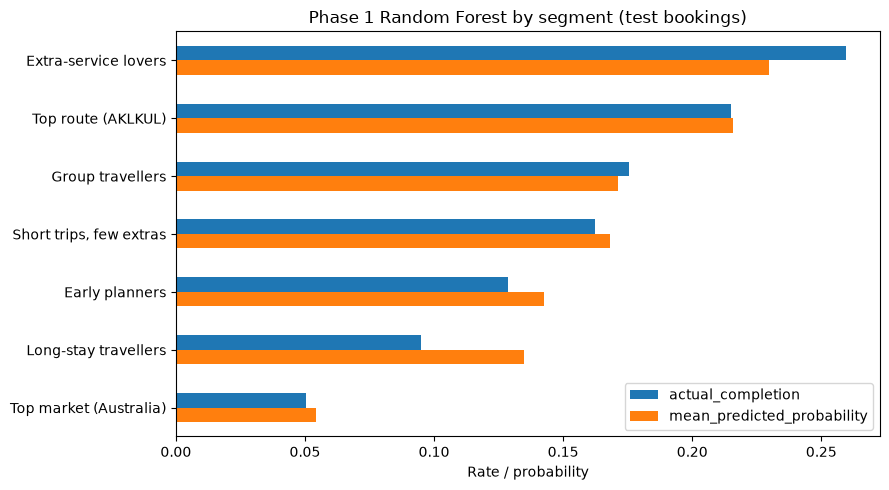

In [24]:
pred_paths = [Path('Supervised_Learning/evaluation_results/model1_predictions.csv'),
              Path('../Supervised_Learning/evaluation_results/model1_predictions.csv')]
pred_path = next((p for p in pred_paths if p.exists()), None)
if pred_path is None:   # e.g. in Colab: read the same file from the main branch on GitHub
    pred_path = ('https://raw.githubusercontent.com/Ghaida-Alyousef/SW485-Project-Group5/'
                 'main/Supervised_Learning/evaluation_results/model1_predictions.csv')
predictions = pd.read_csv(pred_path)

seg_table = pd.DataFrame({'row_id': np.arange(len(data)), 'segment': kmeans_labels,
                          'gmm_confidence': gmm_confidence})
seg_table['segment_name'] = seg_table['segment'].map(names)
joined = predictions.merge(seg_table, on='row_id', how='left')
assert joined['segment'].notna().all() and len(joined) == len(predictions)

segment_predictions = joined.groupby('segment_name').agg(
    test_bookings=('row_id', 'size'),
    actual_completion=('y_true', 'mean'),
    mean_predicted_probability=('y_proba', 'mean'),
    flagged_as_likely_complete=('y_pred_tuned_threshold', 'mean'),
).sort_values('mean_predicted_probability', ascending=False)
display(segment_predictions.round(3))

ax = segment_predictions[['actual_completion', 'mean_predicted_probability']].plot.barh(figsize=(9, 5))
ax.set(title='Phase 1 Random Forest by segment (test bookings)', xlabel='Rate / probability', ylabel='')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'segments_vs_predictions.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation: segments and Phase 1 predictions.** On the 10,011 test bookings, the Random Forest's average predicted probability follows the actual completion rate of each segment closely: for example **5.4% vs. 5.0%** for the Australian market, **21.6% vs. 21.5%** for the AKLKUL route and **23.0% vs. 26.0%** for extra-service lovers. Only the small long-stay segment (179 test bookings) is over-predicted (13.5% vs. 9.5%). At the chosen 0.19 threshold, the model flags **56.8%** of extra-service lovers as likely to complete, but only **1.2%** of the Australian market.

### Integration proposal
1. **Dashboard (segment view).** A segment filter and one KPI card per segment, showing its size, actual completion rate, average predicted probability and share flagged (from `clustering_results/segment_predictions.csv`), plus a chart that compares the segments. Scenario sliders keep the segment fixed while the inputs change, so leaders see how a typical booking in that segment reacts.
2. **Generative AI (personalisation).** The prompt templates receive the booking's segment name and its line from `cluster_profiles.txt` as a `{cluster}` placeholder, for example *"Group travellers: 4.7 passengers on average, 16.7% completion; suggested action: group deals"*. This directly supports the handbook's "personalization: does it reflect the user's context or cluster?" criterion.
3. **New bookings.** A new booking goes through the same preprocessing and scaling, and is then assigned to the **nearest K-Means centroid**, the same rule K-Means uses. Like the Phase 1 Random Forest, the model can be refitted with the saved settings (k = 7, seed 42) instead of loading a file.
4. **Supervised model (optional test).** The segment could be added as an extra feature to the Random Forest. To avoid leakage, the clustering would have to be fitted on the training rows only. A large gain is not expected, because the Random Forest already uses the features that define the segments.

## 14. Challenges & Limitations

- **Weak separation.** Both silhouettes are low (0.159 and 0.096), and the projections overlap. The segments are useful summaries of booking behaviour, not naturally separate customer types.
- **Frequency-encoding side effects.** Standardising the frequency-encoded `booking_origin` and `route` places the most frequent values (Australia and AKLKUL) far from all other bookings, so both algorithms isolate them. These two segments are real groups of bookings, but they reflect market size as much as behaviour. Target encoding, or grouping countries into regions, could be tested in the future.
- **GMM assumptions.** GMM assumes continuous, bell-shaped features. The 15 binary columns made a direct fit fail, PCA (85.6% of the variance) was needed, and GMM still split on the count `num_passengers` (one cluster contains only single-passenger bookings).
- **Sensitivity to the run.** When Section 3 was re-run with a newer scikit-learn version (1.9), the K-Means k-search selected **k = 3 instead of 7**, because the silhouette values of several *k* are very close and were estimated on only 1,800 rows. This is why Sections 9–13 use the saved labels in `clustered_data.csv`, the version shared with the team. The exact clusters should be treated as one reasonable segmentation, not the only possible one.
- **Sampling.** The k-searches use 12,000 bookings and the silhouette uses 10,000, so all values are estimates. t-SNE uses 5,000 bookings and its distances between groups are not meaningful.
- **Completion rates are descriptive.** `booking_complete` was only used after clustering. Differences between segments are associations, not causes.
- **Data quality.** The long-stay segment (stays up to 778 days) may contain data errors and should be checked before any action is taken.
- **All rows were clustered.** Both training and test bookings were clustered, which is fine for describing segments. Using the segment as a feature in a supervised model would require fitting the clustering on the training rows only.

### Saving the results

| File | Content |
| --- | --- |
| `clustering_results/gmm_k_selection.csv` | BIC, silhouette, Davies–Bouldin and smallest cluster for every covariance type and *k* |
| `clustering_results/algorithm_comparison.csv` | All metrics for K-Means and GMM on the same rows |
| `clustering_results/gmm_cluster_labels.csv` | `row_id`, GMM cluster and membership confidence for all 50,000 bookings |
| `clustering_results/segment_profiles.csv` | The profile table of the final segments |
| `clustering_results/segment_predictions.csv` | Phase 1 predictions summarised per segment |
| `clustering_results/run_info.json` | Settings, selected parameters, run times and library versions |
| `clustering_results/*.png` | All figures in Sections 9–13 |
| `cluster_profiles.txt` | Readable profile of every segment, with meaning and suggested action |

In [25]:
import sklearn
gmm_search.to_csv(RESULTS_DIR / 'gmm_k_selection.csv', index=False)
comparison.to_csv(RESULTS_DIR / 'algorithm_comparison.csv')
pd.DataFrame({'row_id': np.arange(len(data)), 'gmm_cluster': gmm_labels,
              'gmm_confidence': gmm_confidence}).to_csv(RESULTS_DIR / 'gmm_cluster_labels.csv', index=False)
profiles_final.drop(columns=['service_score']).to_csv(RESULTS_DIR / 'segment_profiles.csv')
segment_predictions.to_csv(RESULTS_DIR / 'segment_predictions.csv')

run_info = {
    'final_algorithm': 'K-Means',
    'kmeans_k': int(len(np.unique(kmeans_labels))),
    'kmeans_labels_source': str(km_path) if km_path is not None else 'refitted in Section 4',
    'gmm_input': f'PCA, {pca_gmm.n_components_} components ({cum_var[-1]:.1%} of variance)',
    'gmm_covariance_type': best_cov,
    'gmm_k': best_gmm_k,
    'gmm_n_init': 10,
    'gmm_fit_seconds': gmm_fit_seconds,
    'kmeans_fit_seconds': kmeans_fit_seconds,
    'silhouette_sample': 10000,
    'ari_kmeans_vs_gmm': ari,
    'random_state': RANDOM_STATE,
    'sklearn_version': sklearn.__version__,
}
with open(RESULTS_DIR / 'run_info.json', 'w') as f:
    json.dump(run_info, f, indent=2, default=str)

print('Saved files:')
for p in sorted(RESULTS_DIR.iterdir()):
    print('  ', p)
print('  ', BASE_DIR / 'cluster_profiles.txt')

Saved files:
   Unsupervised_Learning\clustering_results\algorithm_comparison.csv
   Unsupervised_Learning\clustering_results\cluster_sizes_kmeans_vs_gmm.png
   Unsupervised_Learning\clustering_results\feature_means_per_cluster.png
   Unsupervised_Learning\clustering_results\gmm_cluster_labels.csv
   Unsupervised_Learning\clustering_results\gmm_k_selection.csv
   Unsupervised_Learning\clustering_results\gmm_k_selection.png
   Unsupervised_Learning\clustering_results\pca_kmeans_vs_gmm.png
   Unsupervised_Learning\clustering_results\run_info.json
   Unsupervised_Learning\clustering_results\segment_predictions.csv
   Unsupervised_Learning\clustering_results\segment_profiles.csv
   Unsupervised_Learning\clustering_results\segments_vs_predictions.png
   Unsupervised_Learning\clustering_results\surrogate_tree_importance.png
   Unsupervised_Learning\clustering_results\tsne_kmeans_vs_gmm.png
   Unsupervised_Learning\cluster_profiles.txt
